機械学習特論 第6回 決定木 で アヤメのデータの分類

In [1]:
# google colab で実行する場合は、次の行の先頭の # を削除してこのブロックを実行する
#!pip install japanize-matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn import metrics

### ml06_decision_tree_iris.ipynb

In [3]:
# sklearnデータセットに収録されたiris(アヤメ)のデータセットをロード
from sklearn.datasets import load_iris
iris_data = load_iris()

# 学習用データのデータフレームを作成
x = pd.DataFrame(iris_data["data"],columns=iris_data["feature_names"])
y = pd.DataFrame(iris_data["target"],columns=["target"])

In [4]:
# データフレームの情報を表示
print('feature shape:', x.shape) # 説明変数の形状
print('feature names:', iris_data["feature_names"]) # 説明変数の列名
print('target shape:', y.shape, y['target'].unique()) # 正解ラベルの形状とクラス名一覧
print('feature null check:\n', x.isnull().any(axis=0))
print('target null check:\n', y.isnull().any(axis=0))

feature shape: (150, 4)
feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
target shape: (150, 1) [0 1 2]
feature null check:
 sepal length (cm)    False
sepal width (cm)     False
petal length (cm)    False
petal width (cm)     False
dtype: bool
target null check:
 target    False
dtype: bool


In [5]:
# データを学習用と検証用に分割
x_train, x_test, y_train, y_test = \
    train_test_split(x, y, test_size=0.25, random_state=2) # 検証用データに25%を割当て
print(f'x_train:{len(x_train)} x_test:{len(x_test)} y_train:{len(y_train)} y_test:{len(y_test)}')

x_train:112 x_test:38 y_train:112 y_test:38


max_depth=3, accuracy_score:  train data :  0.98214 test data :  0.97368


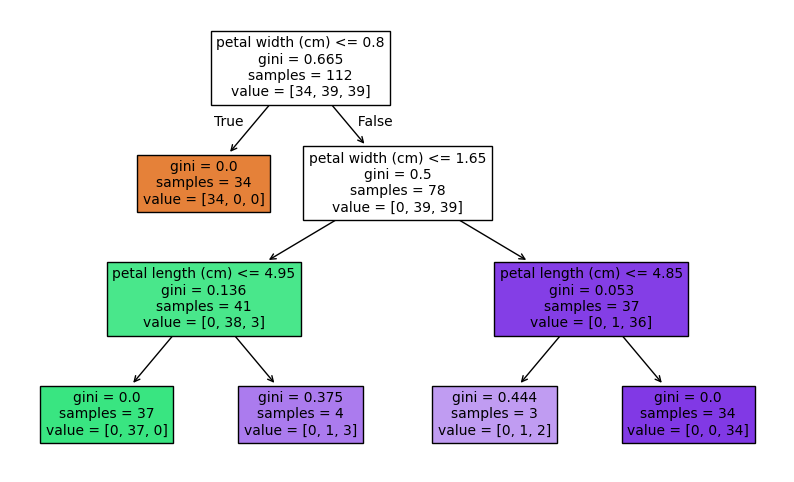

In [6]:
# 決定木を学習データを利用して学習
clf = DecisionTreeClassifier(max_depth=3, # 木の深さの最大
                             random_state=2) # 乱数シード
clf = clf.fit(x_train, y_train['target'])  # * y_trainの列指定はwarning回避のため *

# 学習したモデルの性能(正答率)を学習用データと検証用データで評価
predict_train = clf.predict(x_train)
predict_test = clf.predict(x_test)
print('max_depth=3, accuracy_score: ', 
      f'train data : {metrics.accuracy_score(y_train, predict_train): 0.5}', 
      f'test data : {metrics.accuracy_score(y_test, predict_test): 0.5}')

# 決定木を表示
plt.figure(figsize=[10,6])
plot_tree(clf, feature_names=x_train.columns, filled=True)
plt.show()

In [7]:
# 決定木における各特徴量の重要度を確認
print('Feature_importance:')
for _column, _feature_importance in zip(x.columns, clf.feature_importances_):
    print(f'"{_column}" : {_feature_importance}')

Feature_importance:
"sepal length (cm)" : 0.0
"sepal width (cm)" : 0.0
"petal length (cm)" : 0.06519661391330597
"petal width (cm)" : 0.934803386086694


max_depth=1, accuracy_score:  train data :  0.65179 test data :  0.71053
max_depth=2, accuracy_score:  train data :  0.96429 test data :  0.94737
max_depth=3, accuracy_score:  train data :  0.98214 test data :  0.97368
max_depth=4, accuracy_score:  train data :  1.0 test data :  0.94737
max_depth=5, accuracy_score:  train data :  1.0 test data :  0.94737
max_depth=6, accuracy_score:  train data :  1.0 test data :  0.94737
max_depth=7, accuracy_score:  train data :  1.0 test data :  0.94737


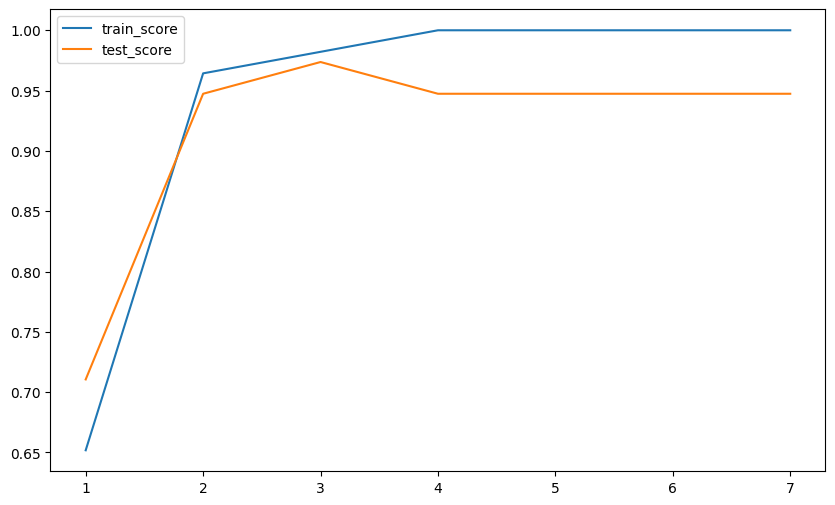

In [8]:
# 木の深さを変えて学習した決定木の性能を学習用データと検証用データで確認
_x = np.linspace(1, 7, 7) # グラフのx軸の設定 (1から7までの7点)
train_score = [] # グラフ用のリスト
test_score = [] # グラフ用のリスト
for i in range(7): # 木の深さは 1-7 (iに1を足して利用)
    # 決定木を学習データを利用して学習
    clf = DecisionTreeClassifier(max_depth=i+1, # 木の深さの最大
                                random_state=1) # 乱数シード
    clf = clf.fit(x_train, y_train['target'])  # * y_trainの列指定はwarning回避のため *

    # 学習したモデルの性能(正答率)を学習用データと検証用データで評価
    # 計算した性能はグラフ用のリストに格納
    predict_train = clf.predict(x_train)
    train_score.append(metrics.accuracy_score(y_train, predict_train))
    predict_test = clf.predict(x_test)
    test_score.append(metrics.accuracy_score(y_test, predict_test))
    print(f'max_depth={i+1}, accuracy_score: ', 
          f'train data : {train_score[i]: 0.5}', 
          f'test data : {test_score[i]: 0.5}')

# 木の深さに対する決定木の性能をグラフで表示
plt.figure(figsize=[10,6])
plt.plot(_x, train_score, label='train_score')
plt.plot(_x, test_score, label='test_score')
plt.legend()
plt.show()

### ml06_decision_tree_mnist.ipynb

In [9]:
# sklearnデータセットに収録されたmnistデータセットをロード
from sklearn.datasets import fetch_openml
# 手書き文字のデータセットをダウンロードして、実験用データを準備 (70000枚のうち7000枚を利用)
mnist_data = fetch_openml('mnist_784')
_x = np.array(mnist_data['data'].astype(np.float32))
_y = np.array(mnist_data['target'].astype(np.int32))
_, x, _, y = train_test_split(_x, _y, test_size=0.1, random_state=1)

In [10]:
# データを学習用と検証用に分割
x_train, x_test, y_train, y_test = \
    train_test_split(x, y, test_size=0.25, random_state=2) # 検証用データに25%を割当て
print(f'x_train:{len(x_train)} x_test:{len(x_test)} y_train:{len(y_train)} y_test:{len(y_test)}')

x_train:5250 x_test:1750 y_train:5250 y_test:1750


max_depth=1, accuracy_score:  train data :  0.20476 test data :  0.192


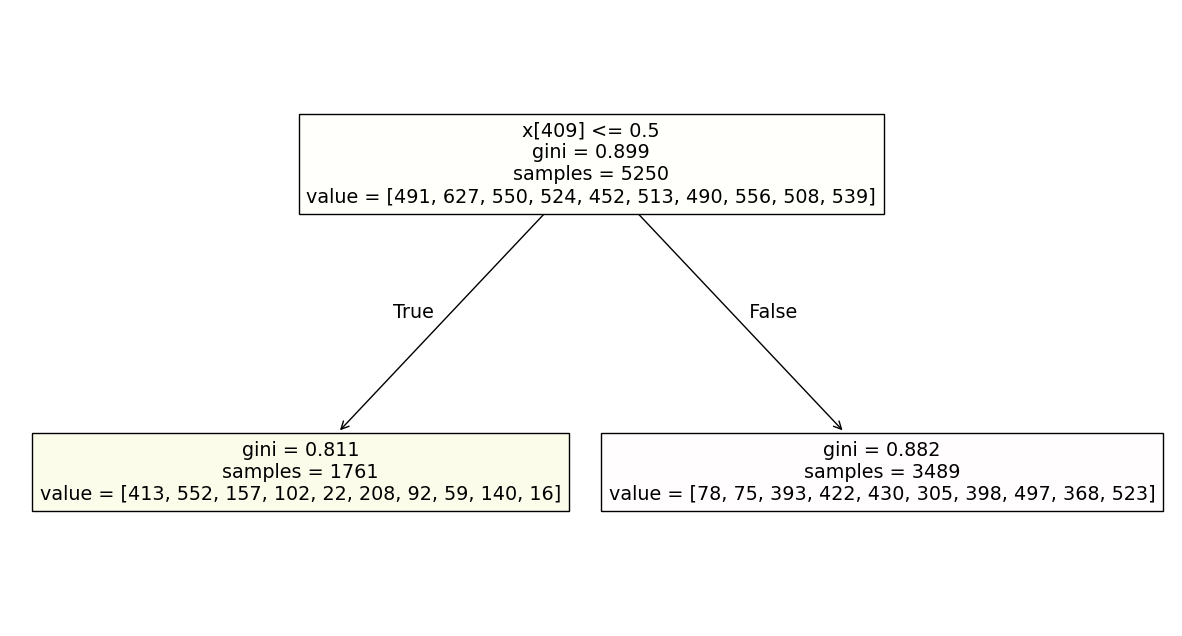

In [11]:
# 決定木を学習データを利用して学習
clf = DecisionTreeClassifier(max_depth=1, # 木の深さの最大
                             random_state=2) # 乱数シード
clf = clf.fit(x_train, y_train)

# 学習したモデルの性能(正答率)を学習用データと検証用データで評価
predict_train = clf.predict(x_train)
predict_test = clf.predict(x_test)
print('max_depth=1, accuracy_score: ', 
      f'train data : {metrics.accuracy_score(y_train, predict_train): 0.5}', 
      f'test data : {metrics.accuracy_score(y_test, predict_test): 0.5}')

# 決定木を表示
plt.figure(figsize=[15,8])
plot_tree(clf, filled=True)
plt.show()

max_depth=1, accuracy_score:  train data :  0.20476 test data :  0.192
max_depth=2, accuracy_score:  train data :  0.33848 test data :  0.34171
max_depth=3, accuracy_score:  train data :  0.47619 test data :  0.46114
max_depth=4, accuracy_score:  train data :  0.62286 test data :  0.608
max_depth=5, accuracy_score:  train data :  0.69352 test data :  0.65314
max_depth=6, accuracy_score:  train data :  0.75867 test data :  0.70914
max_depth=7, accuracy_score:  train data :  0.81638 test data :  0.73257
max_depth=8, accuracy_score:  train data :  0.86705 test data :  0.74229
max_depth=9, accuracy_score:  train data :  0.91562 test data :  0.75429
max_depth=10, accuracy_score:  train data :  0.95314 test data :  0.75429
max_depth=11, accuracy_score:  train data :  0.97467 test data :  0.75314
max_depth=12, accuracy_score:  train data :  0.98857 test data :  0.74514
max_depth=13, accuracy_score:  train data :  0.99352 test data :  0.752
max_depth=14, accuracy_score:  train data :  0.99695 

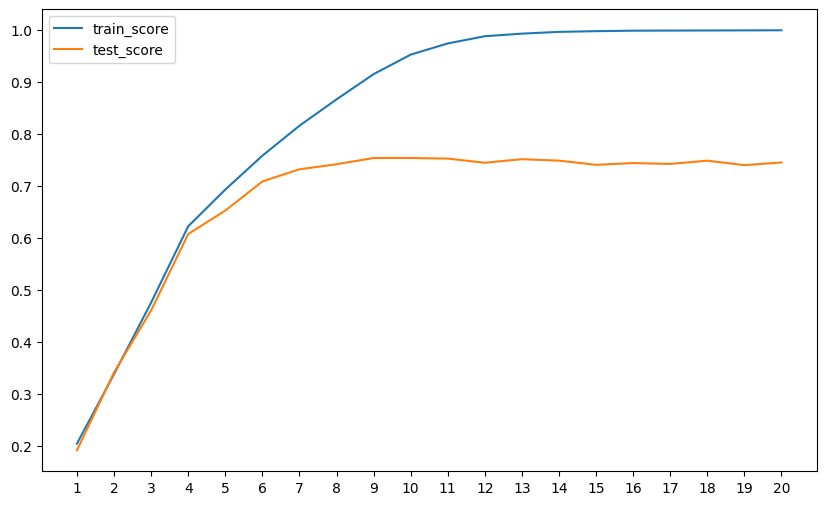

In [12]:
# 木の深さを変えて学習した決定木の性能を学習用データと検証用データで確認
N = 20
_x = np.linspace(1, N, N) # グラフのx軸の設定 (1から7までの7点)
train_score = [] # グラフ用のリスト
test_score = [] # グラフ用のリスト
for i in range(N): # 木の深さは 1-7 (iに1を足して利用)
    # 決定木を学習データを利用して学習
    clf = DecisionTreeClassifier(max_depth=i+1, # 木の深さの最大
                                random_state=1) # 乱数シード
    clf = clf.fit(x_train, y_train)  # * y_trainの列指定はwarning回避のため *

    # 学習したモデルの性能(正答率)を学習用データと検証用データで評価
    # 計算した性能はグラフ用のリストに格納
    predict_train = clf.predict(x_train)
    train_score.append(metrics.accuracy_score(y_train, predict_train))
    predict_test = clf.predict(x_test)
    test_score.append(metrics.accuracy_score(y_test, predict_test))
    print(f'max_depth={i+1}, accuracy_score: ', 
          f'train data : {train_score[i]: 0.5}', 
          f'test data : {test_score[i]: 0.5}')

# 木の深さに対する決定木の性能をグラフで表示
plt.figure(figsize=[10,6])
plt.plot(_x, train_score, label='train_score')
plt.plot(_x, test_score, label='test_score')
plt.legend()
plt.xticks(_x)
plt.show()

max_depth=10, accuracy_score:  train data :  0.95333 test data :  0.75371
重要度がゼロの画素数: 547 / 784 (0.6977040816326531)
重要度が高い画素(上位20件):
0 (378, np.float64(0.06255289950234179)) 0.06255289950234179
1 (409, np.float64(0.05039779367371478)) 0.11295069317605658
2 (155, np.float64(0.0500883405456876)) 0.16303903372174416
3 (432, np.float64(0.04121576250185972)) 0.20425479622360387
4 (211, np.float64(0.03650930136490678)) 0.24076409758851064
5 (657, np.float64(0.03584708140816567)) 0.2766111789966763
6 (462, np.float64(0.032773288927202916)) 0.30938446792387925
7 (487, np.float64(0.02995104075495024)) 0.3393355086788295
8 (319, np.float64(0.029683288994449386)) 0.3690187976732789
9 (377, np.float64(0.026207210233585798)) 0.3952260079068647
10 (550, np.float64(0.022980505348137694)) 0.41820651325500235
11 (347, np.float64(0.018855455855427805)) 0.43706196911043016
12 (296, np.float64(0.018139385135488746)) 0.4552013542459189
13 (485, np.float64(0.017756248329920336)) 0.47295760257583924
14 (542

C:\Users\khiramatsu\AppData\Local\Temp\ipykernel_27084\3133228468.py:34: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.array(np.log(img)).reshape(28,28), cmap=plt.cm.gray_r)


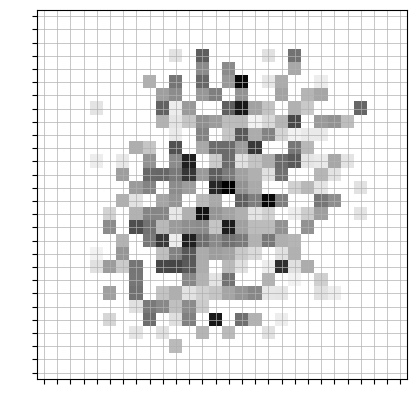

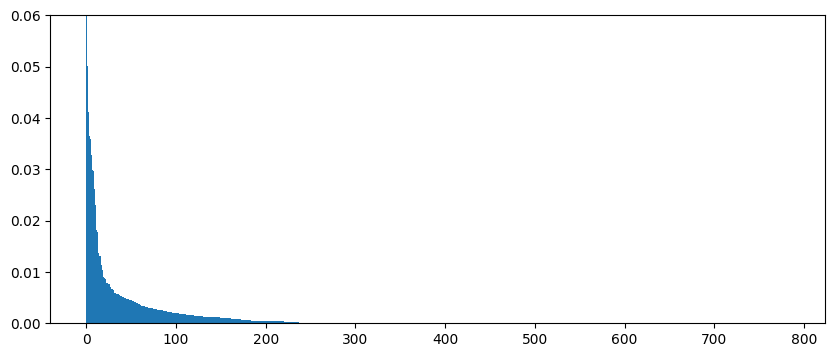

In [13]:
# 決定木を学習データを利用して学習
clf = DecisionTreeClassifier(max_depth=10, # 木の深さの最大
                             random_state=2) # 乱数シード
clf = clf.fit(x_train, y_train)

# 学習したモデルの性能(正答率)を学習用データと検証用データで評価
predict_train = clf.predict(x_train)
predict_test = clf.predict(x_test)
print('max_depth=10, accuracy_score: ', 
      f'train data : {metrics.accuracy_score(y_train, predict_train): 0.5}', 
      f'test data : {metrics.accuracy_score(y_test, predict_test): 0.5}')

# 画素の重要度を確認
importance = {}
img = []
zero_importance = 0
for i in range(len(clf.feature_importances_)):
    importance[i] = clf.feature_importances_[i]
    img.append(clf.feature_importances_[i])
    if clf.feature_importances_[i] == 0.0:
        zero_importance = zero_importance + 1
print('重要度がゼロの画素数:', zero_importance, '/', len(importance), f'({zero_importance/len(importance)})')
print('重要度が高い画素(上位20件):')
importance_sorted = sorted(importance.items(), key=lambda x:x[1], reverse=True)
i = 0
cumulative_importance = 0
for _importance_sorted in importance_sorted:
    cumulative_importance = cumulative_importance + _importance_sorted[1]
    print(i, _importance_sorted, cumulative_importance)
    i = i + 1
    if i > 100:
        break

plt.imshow(np.array(np.log(img)).reshape(28,28), cmap=plt.cm.gray_r)
plt.xticks(np.linspace(0,27,28))
plt.yticks(np.linspace(0,27,28))
plt.xticks(color="None")
plt.yticks(color="None")
plt.grid(linewidth=0.5)
plt.show()

plt.figure(figsize=[10,4])
plt.bar(np.linspace(0,len(img),len(img)), sorted(img, reverse=True), width=1.0)
plt.ylim(0,0.06)
plt.show()

### ml06_decision_tree_all.ipynb

In [14]:
# sklearnデータセットに収録されたiris(アヤメ)のデータセットをロードしてデータフレームを作成
def load_iris_data():
    data = load_iris()
    x = pd.DataFrame(data["data"],columns=data["feature_names"])
    y = pd.DataFrame(data["target"],columns=["target"])
    return x, y

# 手書き文字のデータセットをダウンロードして、実験用データを準備 (70000枚のうち7000枚を利用)
def load_mnist_data():
    data = fetch_openml('mnist_784')
    _x = np.array(data['data'].astype(np.float32))
    _y = np.array(data['target'].astype(np.int32))
    _, x, _, y = train_test_split(_x, _y, test_size=0.1, random_state=1)
    return x, y

# Fashion-MNISTデータセットをダウンロードして、実験用データを準備 (70000枚のうち7000枚を利用)
def load_fashion_mnist_data():
    data = fetch_openml('Fashion-MNIST')
    _x = np.array(data['data'].astype(np.float32))
    _y = np.array(data['target'].astype(np.int32))
    _, x, _, y = train_test_split(_x, _y, test_size=0.1, random_state=1, stratify=_y) 
    return x, y

# 一括処理のためにデータセットの辞書を作成
dataset = {'iris': load_iris_data(), 'mnist': load_mnist_data(), 'fashon-mnist': load_fashion_mnist_data()}

dataset: iris
x_train:112 x_test:38 y_train:112 y_test:38
max_depth=1, accuracy_score:  train data :  0.65179 test data :  0.71053
max_depth=2, accuracy_score:  train data :  0.96429 test data :  0.94737
max_depth=3, accuracy_score:  train data :  0.98214 test data :  0.97368
max_depth=4, accuracy_score:  train data :  1.0 test data :  0.94737
max_depth=5, accuracy_score:  train data :  1.0 test data :  0.94737


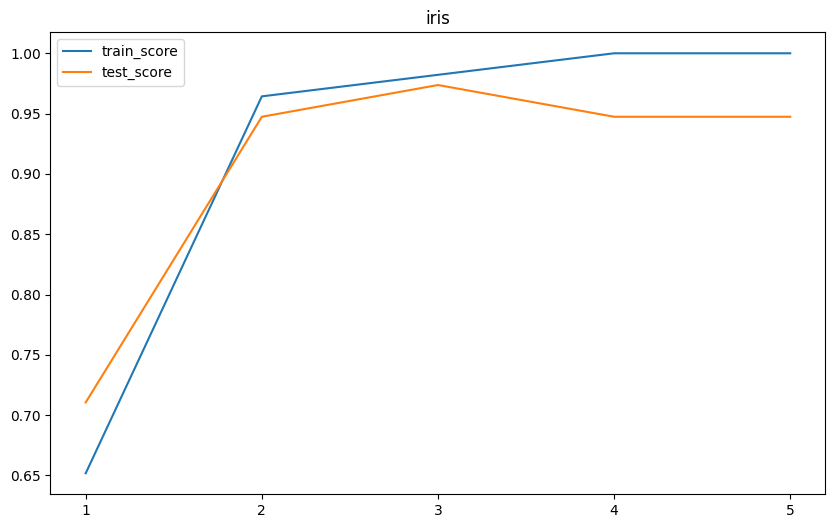

dataset: mnist
x_train:5250 x_test:1750 y_train:5250 y_test:1750
max_depth=1, accuracy_score:  train data :  0.20476 test data :  0.192
max_depth=2, accuracy_score:  train data :  0.33848 test data :  0.34171
max_depth=3, accuracy_score:  train data :  0.47619 test data :  0.46114
max_depth=4, accuracy_score:  train data :  0.62286 test data :  0.608
max_depth=5, accuracy_score:  train data :  0.69352 test data :  0.65257
max_depth=6, accuracy_score:  train data :  0.75943 test data :  0.70857
max_depth=7, accuracy_score:  train data :  0.81619 test data :  0.73486
max_depth=8, accuracy_score:  train data :  0.86705 test data :  0.74629
max_depth=9, accuracy_score:  train data :  0.91524 test data :  0.75029
max_depth=10, accuracy_score:  train data :  0.95333 test data :  0.75371
max_depth=11, accuracy_score:  train data :  0.97467 test data :  0.73886
max_depth=12, accuracy_score:  train data :  0.98819 test data :  0.74457
max_depth=13, accuracy_score:  train data :  0.99352 test da

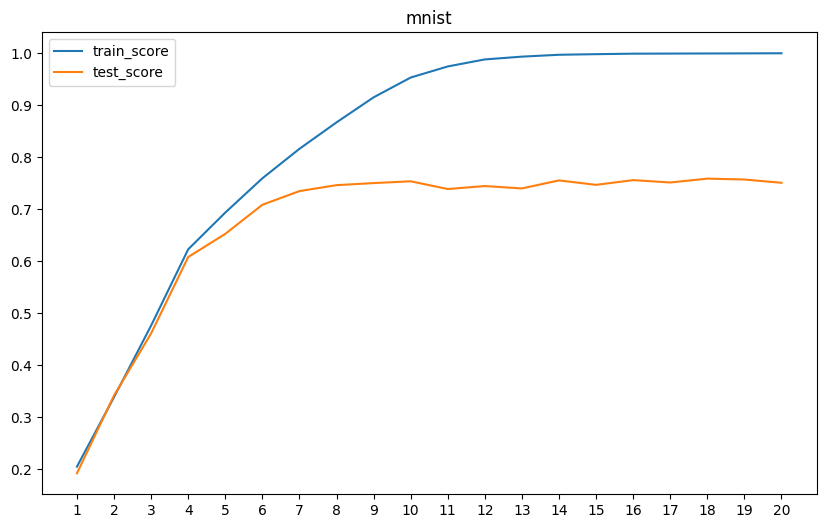

dataset: fashon-mnist
x_train:5250 x_test:1750 y_train:5250 y_test:1750
max_depth=1, accuracy_score:  train data :  0.20324 test data :  0.18571
max_depth=2, accuracy_score:  train data :  0.36267 test data :  0.34343
max_depth=3, accuracy_score:  train data :  0.51029 test data :  0.50057
max_depth=4, accuracy_score:  train data :  0.66019 test data :  0.64229
max_depth=5, accuracy_score:  train data :  0.72419 test data :  0.69714
max_depth=6, accuracy_score:  train data :  0.75733 test data :  0.716
max_depth=7, accuracy_score:  train data :  0.80286 test data :  0.74629
max_depth=8, accuracy_score:  train data :  0.84419 test data :  0.75714
max_depth=9, accuracy_score:  train data :  0.87848 test data :  0.76286
max_depth=10, accuracy_score:  train data :  0.91181 test data :  0.75943
max_depth=11, accuracy_score:  train data :  0.94076 test data :  0.76629
max_depth=12, accuracy_score:  train data :  0.96362 test data :  0.75657
max_depth=13, accuracy_score:  train data :  0.9758

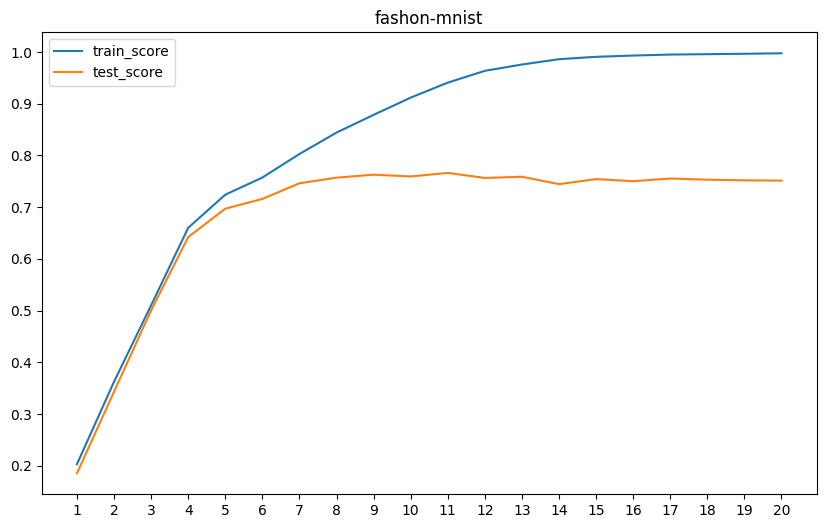

In [15]:
# 辞書に格納したデータセットそれぞれについて木の深さと決定木の性能確認
for _key in dataset.keys():
    print(f'dataset: {_key}')
    x, y = dataset[_key]
    # データを学習用と検証用に分割
    x_train, x_test, y_train, y_test = \
        train_test_split(x, y, test_size=0.25, random_state=2) # 検証用データに25%を割当て
    print(f'x_train:{len(x_train)} x_test:{len(x_test)} y_train:{len(y_train)} y_test:{len(y_test)}')

    # 木の深さを変えて学習した決定木の性能を学習用データと検証用データで確認
    _x = np.linspace(1, 7, 7) # グラフのx軸の設定 (1から7までの7点)
    train_score = [] # グラフ用のリスト
    test_score = [] # グラフ用のリスト
    previous_score = 0.0 # 検証用データに対する正解率を保存

    for i in range(20): # 木の深さは 1-7 (iに1を足して利用)
        # 決定木を学習データを利用して学習
        clf = DecisionTreeClassifier(max_depth=i+1, # 木の深さの最大
                                    random_state=2) # 乱数シード
        clf = clf.fit(x_train, y_train) 

        # 学習したモデルの性能(正答率)を学習用データと検証用データで評価
        # 計算した性能はグラフ用のリストに格納
        predict_train = clf.predict(x_train)
        train_score.append(metrics.accuracy_score(y_train, predict_train))
        predict_test = clf.predict(x_test)
        test_score.append(metrics.accuracy_score(y_test, predict_test))
        print(f'max_depth={i+1}, accuracy_score: ', 
            f'train data : {train_score[i]: 0.5}', 
            f'test data : {test_score[i]: 0.5}')
        if previous_score == test_score[i]:
            break
        previous_score = test_score[i]

    # 木の深さに対する決定木の性能をグラフで表示
    _x = np.linspace(1, i+1, i+1) # グラフのx軸の設定
    plt.figure(figsize=[10,6])
    plt.title(_key)
    plt.plot(_x, train_score, label='train_score')
    plt.plot(_x, test_score, label='test_score')
    plt.xticks(_x)
    plt.legend()
    plt.show()

### ml06_random_forest_mnist.ipynb

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics

In [17]:
from sklearn.datasets import fetch_openml
# 手書き文字のデータセットをダウンロードして、実験用データを準備 (70000枚のうち7000枚を利用)
mnist_data = fetch_openml('mnist_784')
_x = np.array(mnist_data['data'].astype(np.float32))
_y = np.array(mnist_data['target'].astype(np.int32))
_, x, _, y = train_test_split(_x, _y, test_size=0.1, random_state=1)

In [18]:
# データを学習用と検証用に分割
x_train, x_test, y_train, y_test = \
    train_test_split(x, y, test_size=0.25, random_state=2) # 検証用データに25%を割当て
print(f'x_train:{len(x_train)} x_test:{len(x_test)} y_train:{len(y_train)} y_test:{len(y_test)}')

x_train:5250 x_test:1750 y_train:5250 y_test:1750


In [19]:
# 学習データを利用してランダムフォレストを学習
clf = RandomForestClassifier(max_depth=5, # 木の深さの最大
                             n_estimators=10, # 木の数
                             random_state=2) # 乱数シード
clf = clf.fit(x_train, y_train)

# 学習したモデルの性能(正答率)を学習用データと検証用データで評価
predict_train = clf.predict(x_train)
predict_test = clf.predict(x_test)
print('max_depth=5, accuracy_score: ', 
      f'train data : {metrics.accuracy_score(y_train, predict_train): 0.5}', 
      f'test data : {metrics.accuracy_score(y_test, predict_test): 0.5}')

max_depth=5, accuracy_score:  train data :  0.82686 test data :  0.78229


重要度がゼロの画素数: 595 / 784 (0.7589285714285714)
重要度が高い画素(上位20件):
0 (346, np.float64(0.029930852055498752))
1 (351, np.float64(0.02828288669567864))
2 (318, np.float64(0.024972980984361265))
3 (568, np.float64(0.02138555145402842))
4 (354, np.float64(0.020464409603141796))
5 (374, np.float64(0.019307508767401577))
6 (488, np.float64(0.018384470310913385))
7 (409, np.float64(0.018169090594446026))
8 (437, np.float64(0.01815557134049691))
9 (350, np.float64(0.0163762973302272))
10 (290, np.float64(0.016006303259525137))
11 (380, np.float64(0.015975563391768373))
12 (655, np.float64(0.015220518739480316))
13 (152, np.float64(0.014113676203011832))
14 (495, np.float64(0.013898020509672687))
15 (569, np.float64(0.013656357566211013))
16 (358, np.float64(0.013226794185758478))
17 (206, np.float64(0.012911833196255112))
18 (596, np.float64(0.012715779965010329))
19 (486, np.float64(0.012621073563001942))
20 (456, np.float64(0.012351232789534747))


C:\Users\khiramatsu\AppData\Local\Temp\ipykernel_27084\3327962012.py:20: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.array(np.log(img)).reshape(28,28), cmap=plt.cm.gray_r)


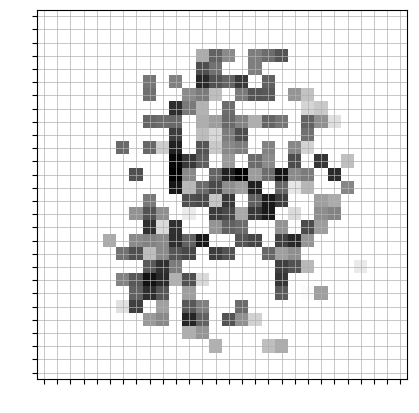

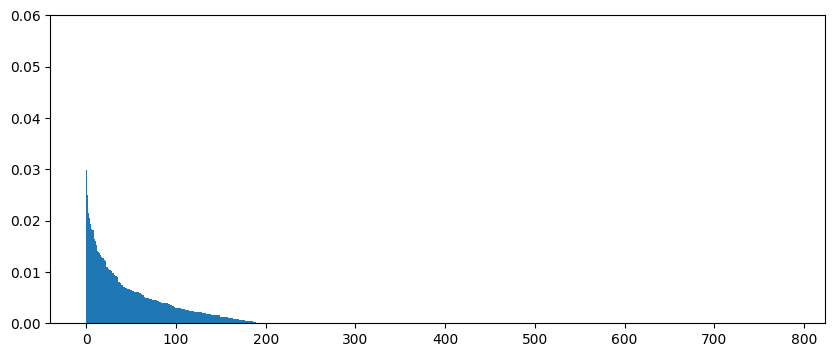

In [20]:
# 画素の重要度を確認
importance = {}
img = []
zero_importance = 0
for i in range(len(clf.feature_importances_)):
    importance[i] = clf.feature_importances_[i]
    img.append(clf.feature_importances_[i])
    if clf.feature_importances_[i] == 0.0:
        zero_importance = zero_importance + 1
print('重要度がゼロの画素数:', zero_importance, '/', len(importance), f'({zero_importance/len(importance)})')
print('重要度が高い画素(上位20件):')
importance_sorted = sorted(importance.items(), key=lambda x:x[1], reverse=True)
i = 0
for _importance_sorted in importance_sorted:
    print(i, _importance_sorted)
    i = i + 1
    if i > 20:
        break

plt.imshow(np.array(np.log(img)).reshape(28,28), cmap=plt.cm.gray_r)
plt.xticks(np.linspace(0,27,28))
plt.yticks(np.linspace(0,27,28))
plt.xticks(color="None")
plt.yticks(color="None")
plt.grid(linewidth=0.5)
plt.show()

plt.figure(figsize=[10,4])
plt.bar(np.linspace(0,len(img),len(img)), sorted(img, reverse=True), width=1.0)
plt.ylim(0,0.06)
plt.show()

In [21]:
# ランダムフォレストの木の深さ、木の数を変え、学習用データと検証用データで性能を確認
train_score = [] # グラフ用のリスト
test_score = [] # グラフ用のリスト
N = 20
for i in range(N): # 木の深さ (1-(N-1) iに1を足して利用)
    for j in range(N): # 木の数 (1-(N-1) jに1を足して利用)
        # ランダムフォレストを学習データを利用して学習
        clf = RandomForestClassifier(max_depth=i+1, # 木の深さの最大
                                     n_estimators=j+1, # 木の数
                                     random_state=2) # 乱数シード
        clf = clf.fit(x_train, y_train)

        # 学習したモデルの性能(正答率)を学習用データと検証用データで評価
        # 計算した性能はグラフ用のリストに格納
        predict_train = clf.predict(x_train)
        train_score.append(metrics.accuracy_score(y_train, predict_train))
        predict_test = clf.predict(x_test)
        test_score.append(metrics.accuracy_score(y_test, predict_test))
        print(f'max_depth={i+1}, n_estimators={j+1} accuracy_score: ', 
            f'train data : {train_score[i*N+j]: 0.5}', 
            f'test data : {test_score[i*N+j]: 0.5}')

max_depth=1, n_estimators=1 accuracy_score:  train data :  0.19867 test data :  0.18686
max_depth=1, n_estimators=2 accuracy_score:  train data :  0.3059 test data :  0.29429
max_depth=1, n_estimators=3 accuracy_score:  train data :  0.27943 test data :  0.28286
max_depth=1, n_estimators=4 accuracy_score:  train data :  0.27752 test data :  0.27143
max_depth=1, n_estimators=5 accuracy_score:  train data :  0.31638 test data :  0.30743
max_depth=1, n_estimators=6 accuracy_score:  train data :  0.35752 test data :  0.34
max_depth=1, n_estimators=7 accuracy_score:  train data :  0.36267 test data :  0.35657
max_depth=1, n_estimators=8 accuracy_score:  train data :  0.34514 test data :  0.33143
max_depth=1, n_estimators=9 accuracy_score:  train data :  0.37257 test data :  0.36286
max_depth=1, n_estimators=10 accuracy_score:  train data :  0.36114 test data :  0.35086
max_depth=1, n_estimators=11 accuracy_score:  train data :  0.36114 test data :  0.34629
max_depth=1, n_estimators=12 accur

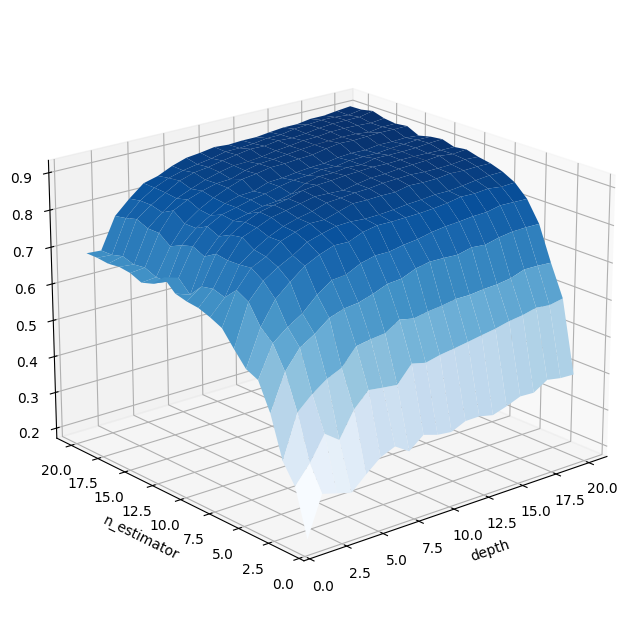

In [22]:
# 木の深さ、木の数に対するランダムフォレストの性能をグラフで表示
x1 = np.linspace(1, N, N)
x2 = np.linspace(1, N, N)
X1, X2 = np.meshgrid(x1, x2)
fig = plt.figure(figsize=[15,8])
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X1, X2, np.array(test_score).reshape(N,N), cmap='Blues')
ax.view_init(elev=20, azim=-130)
ax.set_xlabel('depth')
ax.set_ylabel('n_estimator')
ax.set_zlabel('accuracy')
plt.show()

max_depth=1, accuracy_score:  train data :  0.81771 test data :  0.66686
max_depth=2, accuracy_score:  train data :  0.87429 test data :  0.70629
max_depth=3, accuracy_score:  train data :  0.92857 test data :  0.77029
max_depth=4, accuracy_score:  train data :  0.95467 test data :  0.82
max_depth=5, accuracy_score:  train data :  0.96343 test data :  0.83543
max_depth=6, accuracy_score:  train data :  0.9701 test data :  0.852
max_depth=7, accuracy_score:  train data :  0.97505 test data :  0.86
max_depth=8, accuracy_score:  train data :  0.98152 test data :  0.86857
max_depth=9, accuracy_score:  train data :  0.98248 test data :  0.87714
max_depth=10, accuracy_score:  train data :  0.98343 test data :  0.876
max_depth=11, accuracy_score:  train data :  0.98476 test data :  0.87429
max_depth=12, accuracy_score:  train data :  0.98648 test data :  0.88171
max_depth=13, accuracy_score:  train data :  0.98705 test data :  0.888
max_depth=14, accuracy_score:  train data :  0.98857 test da

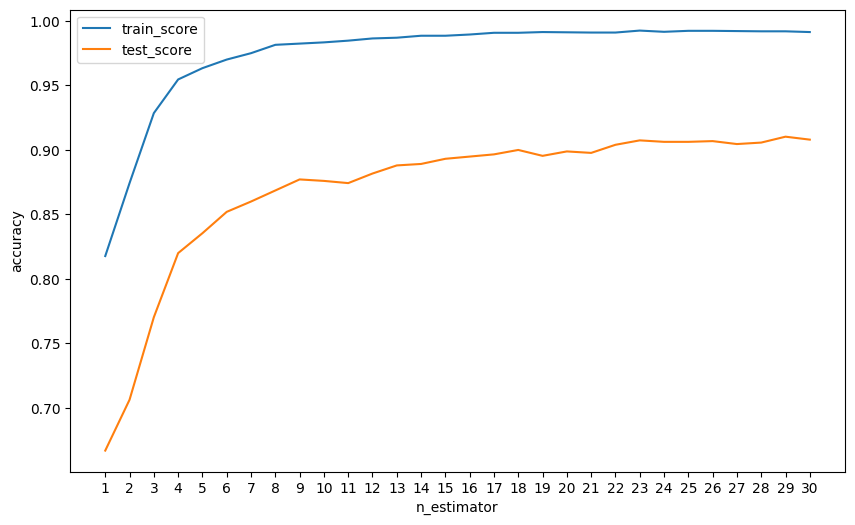

In [23]:
# 木の数を変えて学習したランダムフォレストの性能を学習用データと検証用データで確認
N = 30
_x = np.linspace(1, N, N) # グラフのx軸の設定 (1から7までの7点)
train_score = [] # グラフ用のリスト
test_score = [] # グラフ用のリスト
for i in range(N):
    clf = RandomForestClassifier(max_depth=10, # 木の深さの最大
                                    n_estimators=i+1, # 木の数
                                    random_state=2) # 乱数シード
    clf = clf.fit(x_train, y_train)  # * y_trainの列指定はwarning回避のため *

    # 学習したモデルの性能(正答率)を学習用データと検証用データで評価
    predict_train = clf.predict(x_train)
    train_score.append(metrics.accuracy_score(y_train, predict_train))
    predict_test = clf.predict(x_test)
    test_score.append(metrics.accuracy_score(y_test, predict_test))
    print(f'max_depth={i+1}, accuracy_score: ', 
            f'train data : {train_score[i]: 0.5}', 
            f'test data : {test_score[i]: 0.5}')

# 木の深さに対する決定木の性能をグラフで表示
plt.figure(figsize=[10,6])
plt.plot(_x, train_score, label='train_score')
plt.plot(_x, test_score, label='test_score')
plt.xlabel('n_estimator')
plt.ylabel('accuracy')
plt.xticks(_x)
plt.legend()
plt.show()

max_depth=1, accuracy_score:  train data :  0.36114 test data :  0.35086
max_depth=2, accuracy_score:  train data :  0.54076 test data :  0.52857
max_depth=3, accuracy_score:  train data :  0.65981 test data :  0.632
max_depth=4, accuracy_score:  train data :  0.74648 test data :  0.724
max_depth=5, accuracy_score:  train data :  0.82686 test data :  0.78229
max_depth=6, accuracy_score:  train data :  0.872 test data :  0.83886
max_depth=7, accuracy_score:  train data :  0.91524 test data :  0.844
max_depth=8, accuracy_score:  train data :  0.94667 test data :  0.87257
max_depth=9, accuracy_score:  train data :  0.97276 test data :  0.87543
max_depth=10, accuracy_score:  train data :  0.98343 test data :  0.876
max_depth=11, accuracy_score:  train data :  0.99219 test data :  0.88629
max_depth=12, accuracy_score:  train data :  0.99524 test data :  0.87943
max_depth=13, accuracy_score:  train data :  0.99714 test data :  0.87657
max_depth=14, accuracy_score:  train data :  0.99733 test

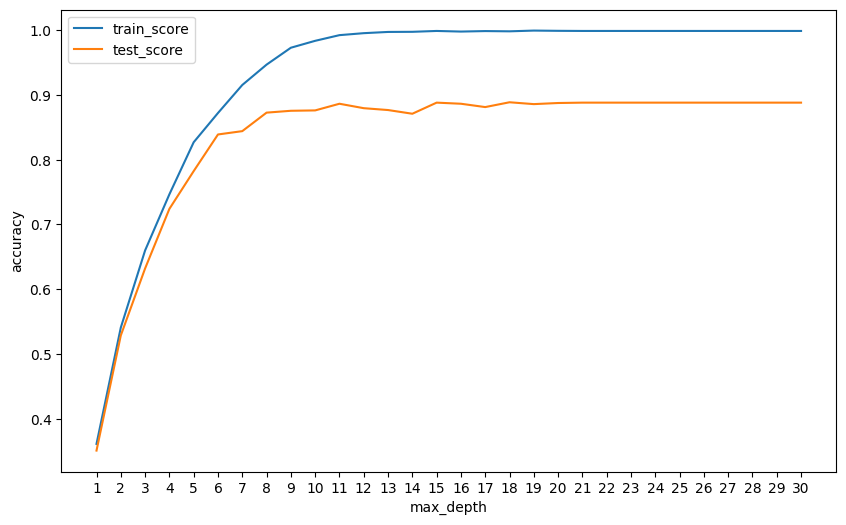

In [24]:
# 木の数を変えて学習したランダムフォレストの性能を学習用データと検証用データで確認
N = 30
_x = np.linspace(1, N, N) # グラフのx軸の設定 (1から7までの7点)
train_score = [] # グラフ用のリスト
test_score = [] # グラフ用のリスト
for i in range(N):
    clf = RandomForestClassifier(max_depth=i+1, # 木の深さの最大
                                    n_estimators=10, # 木の数
                                    random_state=2) # 乱数シード
    clf = clf.fit(x_train, y_train)  # * y_trainの列指定はwarning回避のため *

    # 学習したモデルの性能(正答率)を学習用データと検証用データで評価
    predict_train = clf.predict(x_train)
    train_score.append(metrics.accuracy_score(y_train, predict_train))
    predict_test = clf.predict(x_test)
    test_score.append(metrics.accuracy_score(y_test, predict_test))
    print(f'max_depth={i+1}, accuracy_score: ', 
            f'train data : {train_score[i]: 0.5}', 
            f'test data : {test_score[i]: 0.5}')

# 木の深さに対する決定木の性能をグラフで表示
plt.figure(figsize=[10,6])
plt.plot(_x, train_score, label='train_score')
plt.plot(_x, test_score, label='test_score')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.xticks(_x)
plt.legend()
plt.show()

### ml06_adaboost_mnist.ipynb

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn import metrics

In [26]:
from sklearn.datasets import fetch_openml
# 手書き文字のデータセットをダウンロードして、実験用データを準備 (70000枚のうち7000枚を利用)
mnist_data = fetch_openml('mnist_784')
_x = np.array(mnist_data['data'].astype(np.float32))
_y = np.array(mnist_data['target'].astype(np.int32))
_, x, _, y = train_test_split(_x, _y, test_size=0.1, random_state=1)

In [27]:
# データを学習用と検証用に分割
x_train, x_test, y_train, y_test = \
    train_test_split(x, y, test_size=0.25, random_state=2) # 検証用データに25%を割当て
print(f'x_train:{len(x_train)} x_test:{len(x_test)} y_train:{len(y_train)} y_test:{len(y_test)}')

x_train:5250 x_test:1750 y_train:5250 y_test:1750


In [28]:
# アダブーストのためのベースモデル(決定木)を作成 (指定がないと深さ1の決定木を利用)
base_clf = DecisionTreeClassifier(max_depth=5, random_state=1)
# 学習データを利用してアダブーストを学習
clf = AdaBoostClassifier(estimator=base_clf, # ベースモデルを指定
                         random_state=1) # 乱数シード
clf = clf.fit(x_train, y_train)

# 学習したモデルの性能(正答率)を学習用データと検証用データで評価
predict_train = clf.predict(x_train)
predict_test = clf.predict(x_test)
print('max_depth=10, accuracy_score: ', 
      f'train data : {metrics.accuracy_score(y_train, predict_train): 0.5}', 
      f'test data : {metrics.accuracy_score(y_test, predict_test): 0.5}')

max_depth=10, accuracy_score:  train data :  0.97581 test data :  0.87371


In [29]:
# 木の数を変えて学習したアダブーストの性能を学習用データと検証用データで確認
N = 20
_x = np.linspace(10, N*10, N) # グラフのx軸の設定 (1から7までの7点)
dct_train_score = [] # グラフ用のリスト
dct_test_score = []
adb_train_score = [] # グラフ用のリスト
adb_test_score = [] 
MAX_DEPTH = 5
for i in range(N):
    # 学習データを利用してアダブーストを学習
    base_clf = DecisionTreeClassifier(max_depth=MAX_DEPTH, random_state=1)
    clf = AdaBoostClassifier(estimator=base_clf, # ベースモデルを指定
                             n_estimators=(i+1)*10, # 木の数は10ずつ増やして性能を計測
                             random_state=1) # 乱数シード
    clf = clf.fit(x_train, y_train)  # * y_trainの列指定はwarning回避のため *

    # 学習したモデルの性能(正答率)を学習用データと検証用データで評価
    predict_train = clf.predict(x_train)
    adb_train_score.append(metrics.accuracy_score(y_train, predict_train))
    predict_test = clf.predict(x_test)
    adb_test_score.append(metrics.accuracy_score(y_test, predict_test))
    print(f'ADB max_depth={i+1}*{MAX_DEPTH}, accuracy_score: ', 
            f'train data : {adb_train_score[i]: 0.5}', 
            f'test data : {adb_test_score[i]: 0.5}')

ADB max_depth=1*5, accuracy_score:  train data :  0.86838 test data :  0.79486
ADB max_depth=2*5, accuracy_score:  train data :  0.93067 test data :  0.82971
ADB max_depth=3*5, accuracy_score:  train data :  0.95638 test data :  0.85543
ADB max_depth=4*5, accuracy_score:  train data :  0.97067 test data :  0.86686
ADB max_depth=5*5, accuracy_score:  train data :  0.97581 test data :  0.87371
ADB max_depth=6*5, accuracy_score:  train data :  0.98362 test data :  0.86971
ADB max_depth=7*5, accuracy_score:  train data :  0.98457 test data :  0.88286
ADB max_depth=8*5, accuracy_score:  train data :  0.98686 test data :  0.888
ADB max_depth=9*5, accuracy_score:  train data :  0.99257 test data :  0.88571
ADB max_depth=10*5, accuracy_score:  train data :  0.99276 test data :  0.89029
ADB max_depth=11*5, accuracy_score:  train data :  0.99162 test data :  0.89257
ADB max_depth=12*5, accuracy_score:  train data :  0.99333 test data :  0.89886
ADB max_depth=13*5, accuracy_score:  train data :  

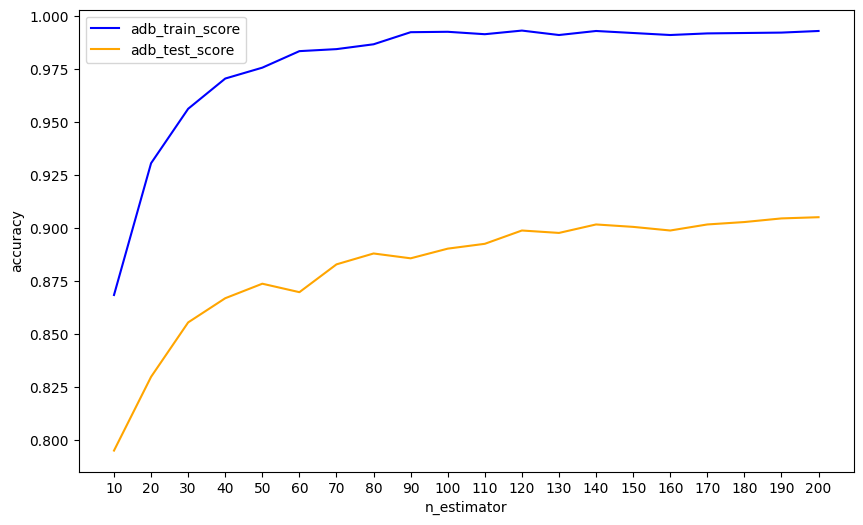

In [30]:
# 木の深さに対する決定木の性能をグラフで表示
plt.figure(figsize=[10,6])
plt.plot(_x, adb_train_score, label='adb_train_score', color="blue")
plt.plot(_x, adb_test_score, label='adb_test_score', color="orange")
plt.xlabel('n_estimator')
plt.ylabel('accuracy')
plt.xticks(_x)
plt.legend()
plt.show()

In [31]:
# 木の数を変えて学習したアダブーストの性能を学習用データと検証用データで確認
N = 20
_x = np.linspace(10, N*10, N) # グラフのx軸の設定 (1から7までの7点)
dct_train_score = [] # グラフ用のリスト
dct_test_score = []
adb_train_score = [] # グラフ用のリスト
adb_test_score = [] 
MAX_DEPTH = 10
for i in range(N):
    # 学習データを利用してアダブーストを学習
    base_clf = DecisionTreeClassifier(max_depth=MAX_DEPTH, random_state=1)
    clf = AdaBoostClassifier(estimator=base_clf, # ベースモデルを指定
                             n_estimators=(i+1)*10, # 木の数は10ずつ増やして性能を計測
                             random_state=1) # 乱数シード
    clf = clf.fit(x_train, y_train)  # * y_trainの列指定はwarning回避のため *

    # 学習したモデルの性能(正答率)を学習用データと検証用データで評価
    predict_train = clf.predict(x_train)
    adb_train_score.append(metrics.accuracy_score(y_train, predict_train))
    predict_test = clf.predict(x_test)
    adb_test_score.append(metrics.accuracy_score(y_test, predict_test))
    print(f'ADB max_depth={i+1}*{MAX_DEPTH}, accuracy_score: ', 
            f'train data : {adb_train_score[i]: 0.5}', 
            f'test data : {adb_test_score[i]: 0.5}')

ADB max_depth=1*10, accuracy_score:  train data :  1.0 test data :  0.85543
ADB max_depth=2*10, accuracy_score:  train data :  1.0 test data :  0.89371
ADB max_depth=3*10, accuracy_score:  train data :  1.0 test data :  0.90514
ADB max_depth=4*10, accuracy_score:  train data :  1.0 test data :  0.91143
ADB max_depth=5*10, accuracy_score:  train data :  1.0 test data :  0.91714
ADB max_depth=6*10, accuracy_score:  train data :  1.0 test data :  0.91714
ADB max_depth=7*10, accuracy_score:  train data :  1.0 test data :  0.91714
ADB max_depth=8*10, accuracy_score:  train data :  1.0 test data :  0.92057
ADB max_depth=9*10, accuracy_score:  train data :  1.0 test data :  0.92171
ADB max_depth=10*10, accuracy_score:  train data :  1.0 test data :  0.92514
ADB max_depth=11*10, accuracy_score:  train data :  1.0 test data :  0.928
ADB max_depth=12*10, accuracy_score:  train data :  1.0 test data :  0.93029
ADB max_depth=13*10, accuracy_score:  train data :  1.0 test data :  0.928
ADB max_dept

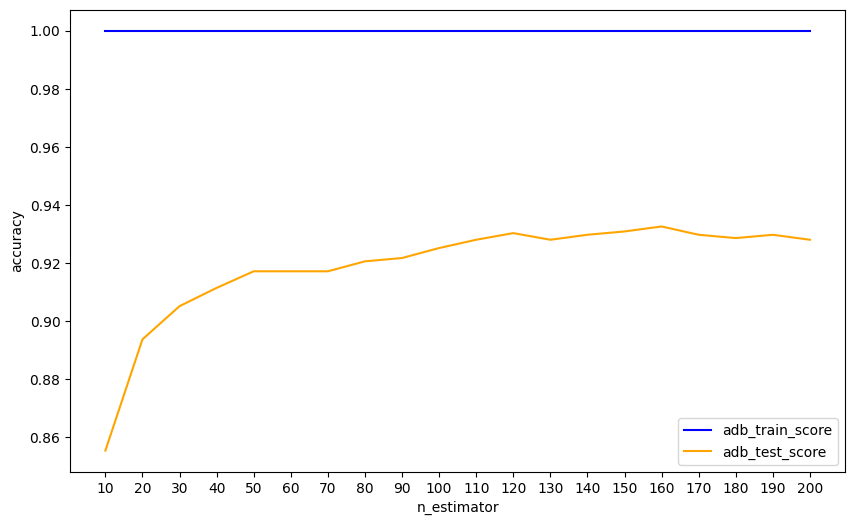

In [32]:
# 木の深さに対する決定木の性能をグラフで表示
plt.figure(figsize=[10,6])
plt.plot(_x, adb_train_score, label='adb_train_score', color="blue")
plt.plot(_x, adb_test_score, label='adb_test_score', color="orange")
plt.xlabel('n_estimator')
plt.ylabel('accuracy')
plt.xticks(_x)
plt.legend()
plt.show()

### ml06_gb_mnist.ipynb

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn import metrics

In [34]:
from sklearn.datasets import fetch_openml
# 手書き文字のデータセットをダウンロードして、実験用データを準備 (70000枚のうち7000枚を利用)
mnist_data = fetch_openml('mnist_784')
_x = np.array(mnist_data['data'].astype(np.float32))
_y = np.array(mnist_data['target'].astype(np.int32))
_, x, _, y = train_test_split(_x, _y, test_size=0.1, random_state=1)

In [35]:
# データを学習用と検証用に分割
x_train, x_test, y_train, y_test = \
    train_test_split(x, y, test_size=0.25, random_state=2) # 検証用データに25%を割当て
print(f'x_train:{len(x_train)} x_test:{len(x_test)} y_train:{len(y_train)} y_test:{len(y_test)}')

x_train:5250 x_test:1750 y_train:5250 y_test:1750


In [36]:
# 学習データを利用して勾配ブースティングを学習
clf = GradientBoostingClassifier(max_depth=5, # 木の深さの最大を設定
                                 random_state=1) # 乱数シード
clf = clf.fit(x_train, y_train)

# 学習したモデルの性能(正答率)を学習用データと検証用データで評価
predict_train = clf.predict(x_train)
predict_test = clf.predict(x_test)
print('max_depth=5, accuracy_score: ', 
      f'train data : {metrics.accuracy_score(y_train, predict_train): 0.5}', 
      f'test data : {metrics.accuracy_score(y_test, predict_test): 0.5}')

max_depth=5, accuracy_score:  train data :  1.0 test data :  0.92114


In [37]:
# 木の数を変えて学習したアダブーストの性能を学習用データと検証用データで確認
N = 10
_x = np.linspace(20, N*20, N) # グラフのx軸の設定 (1から7までの7点)
dct_train_score = [] # グラフ用のリスト
dct_test_score = []
adb_train_score = [] # グラフ用のリスト
adb_test_score = [] 
for i in range(N):
    # 学習データを利用して勾配ブースティングを学習
    clf = GradientBoostingClassifier(max_depth=5,  # 木の深さの最大を設定
                                     n_estimators=(i+1)*20, # 木の数は20ずつ増やして性能を計測
                                     random_state=1) # 乱数シード
    clf = clf.fit(x_train, y_train) 

    # 学習したモデルの性能(正答率)を学習用データと検証用データで評価
    predict_train = clf.predict(x_train)
    adb_train_score.append(metrics.accuracy_score(y_train, predict_train))
    predict_test = clf.predict(x_test)
    adb_test_score.append(metrics.accuracy_score(y_test, predict_test))
    print(f'GB n_estimators={(i+1)*20}, accuracy_score: ', 
            f'train data : {adb_train_score[i]: 0.5}', 
            f'test data : {adb_test_score[i]: 0.5}')

GB n_estimators=20, accuracy_score:  train data :  0.98876 test data :  0.89314
GB n_estimators=40, accuracy_score:  train data :  1.0 test data :  0.90571
GB n_estimators=60, accuracy_score:  train data :  1.0 test data :  0.91657
GB n_estimators=80, accuracy_score:  train data :  1.0 test data :  0.92
GB n_estimators=100, accuracy_score:  train data :  1.0 test data :  0.92114
GB n_estimators=120, accuracy_score:  train data :  1.0 test data :  0.92229
GB n_estimators=140, accuracy_score:  train data :  1.0 test data :  0.924
GB n_estimators=160, accuracy_score:  train data :  1.0 test data :  0.92571
GB n_estimators=180, accuracy_score:  train data :  1.0 test data :  0.92914
GB n_estimators=200, accuracy_score:  train data :  1.0 test data :  0.928


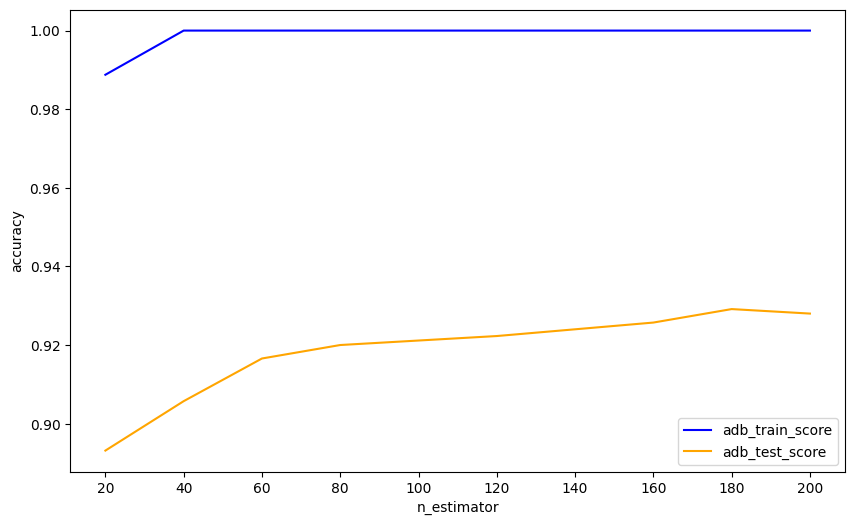

In [38]:
# 木の深さに対する決定木の性能をグラフで表示
plt.figure(figsize=[10,6])
plt.plot(_x, adb_train_score, label='adb_train_score', color="blue")
plt.plot(_x, adb_test_score, label='adb_test_score', color="orange")
plt.xlabel('n_estimator')
plt.ylabel('accuracy')
plt.xticks(_x)
plt.legend()
plt.show()